# Stage 10B — Fixed-250 feature contribution, Morgan highlights, and MolSHAP

Run cells in order. Stage 05 already selected the **fixed 250 features** used by the final models. This notebook reuses that exact list; it does not reload all 3,291 candidate descriptors or select features again. In the ablation log, `all_features` means all 250 fixed Stage 05 features.

1. **Family contribution:** summarize Stage 10 SHAP values by family for the final ExtraTrees and CatBoost models. A fixed-250 leave-one-family-out scaffold-CV sensitivity check is also available. It removes features only from the fixed list and never re-ranks descriptors. Because Stage 05 selected the list using the full training partition, this sensitivity check is descriptive and is not a new unbiased CV estimate.
2. **Morgan structural highlights:** map the final Stage 08 models’ Stage 10 SHAP contributions for Morgan bits onto locked-test structures. No Morgan-only auxiliary model is fitted. If the fixed 250 contains no Morgan bits, that model will have no Morgan-bit map.
3. **MolSHAP:** run the authors’ implementation on a congeneric series from training molecules only. MolSHAP explains R-group contributions in that series; it is a separate supplementary analysis.

The notebook reads test structures for the drawings, but never test activities. Outputs are saved under `outputs/10b_interpretation/`. Positive SHAP values raise the model prediction; negative values lower it. Hashed Morgan bits can collide, so atom-environment mappings are saved with each figure.


In [2]:
# 1. Locate the project and import Stage 10B helpers.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Open the notebook from the BRD4 QSAR project folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from IPython.display import display, Image
import pandas as pd
from src.utils import OUTPUTS
from src.feature_selection import family as feature_family
from src.interpretation_10b import (
    run_fixed250_family_ablation,
    summarize_fixed250_shap_families,
    draw_fixed250_morgan_highlights,
)

STAGE_DIR = OUTPUTS / "10b_interpretation"
(STAGE_DIR / "tables").mkdir(parents=True, exist_ok=True)
(STAGE_DIR / "figures").mkdir(parents=True, exist_ok=True)
print(f"Project: {PROJECT_ROOT}")
print(f"Stage 10B output folder: {STAGE_DIR}")
print("Next: verify Stage 05 fixed-250 and Stage 10 SHAP outputs.")


Project: c:\Users\USER\Documents\E\Code
Stage 10B output folder: C:\Users\USER\Documents\E\Code\outputs\10b_interpretation
Next: verify Stage 05 fixed-250 and Stage 10 SHAP outputs.


In [3]:
# 2. Check the fixed-250 input and SHAP outputs, then display the fixed feature composition.
required = [
    OUTPUTS / "05_feature_selection/tables/train_selected_features.parquet",
    OUTPUTS / "05_feature_selection/tables/train_target.parquet",
    OUTPUTS / "05_feature_selection/tables/selected_features.csv",
    OUTPUTS / "04_train_test_split/tables/train_ids.csv",
    OUTPUTS / "04_train_test_split/tables/test_ids.csv",
    OUTPUTS / "02_clean_data/tables/cleaned_activity.csv",
    OUTPUTS / "07_optuna_tuning/tables/optuna_best_params.json",
    OUTPUTS / "08_final_model_evaluation/tables/locked_test_predictions_all_models.csv",
    OUTPUTS / "08_final_model_evaluation/models/final_ExtraTreesRegressor.joblib",
    OUTPUTS / "08_final_model_evaluation/models/final_CatBoostRegressor.joblib",
    OUTPUTS / "10_shap_interpretation/tables/test_shap_values_ExtraTreesRegressor.parquet",
    OUTPUTS / "10_shap_interpretation/tables/test_shap_values_CatBoostRegressor.parquet",
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Run the earlier stages first. Missing:\n" + "\n".join(missing))
selected = pd.read_csv(OUTPUTS / "05_feature_selection/tables/selected_features.csv")["feature"].astype(str)
if len(selected) != 250 or selected.nunique() != 250:
    raise ValueError(f"Expected exactly 250 fixed Stage 05 features; found {len(selected)}.")
X_fixed = pd.read_parquet(OUTPUTS / "05_feature_selection/tables/train_selected_features.parquet")
if X_fixed.shape[1] != 250 or set(X_fixed.columns.astype(str)) != set(selected):
    raise ValueError("Stage 05 training matrix does not match the fixed 250-feature list.")
family_counts = selected.map(feature_family).value_counts().rename_axis("feature_family").reset_index(name="n_fixed_features")
display(family_counts)
print(f"Using exactly {len(selected)} Stage 05 features. The 3,291 complete finite candidates were an earlier selection pool and are not used here.")
print("Next: summarize family-level SHAP contributions for the existing Stage 08 models.")


,feature_family,n_fixed_features
0,Mordred 2D,146
1,Morgan,103
2,Physicochemical,1


Using exactly 250 Stage 05 features. The 3,291 complete finite candidates were an earlier selection pool and are not used here.
Next: summarize family-level SHAP contributions for the existing Stage 08 models.


In [4]:
# 3. Summarize Stage 10 SHAP contributions by feature family for the final models.
# This uses saved Stage 10 explanations; it does not refit models or select features.
family_shap_summary, family_shap_by_molecule = summarize_fixed250_shap_families()
display(family_shap_summary.sort_values(["model", "mean_abs_family_contribution"], ascending=[True, False]))
print("Saved family totals for each test molecule and model. Next: run a fixed-250 family-removal sensitivity check with ExtraTrees.")


,model,feature_family,n_features,mean_abs_family_contribution,mean_signed_family_contribution,share_of_total_abs_contribution_pct
5,CatBoostRegressor,Mordred 2D,146,1.294147,0.007463,60.133246
4,CatBoostRegressor,Morgan,103,0.844896,-0.043740,39.258556
7,CatBoostRegressor,Physicochemical,1,0.013089,-0.000518,0.608199
6,CatBoostRegressor,Mordred 3D,0,0.000000,0.000000,0.000000
0,ExtraTreesRegressor,Morgan,103,1.278895,-0.050074,67.929077
1,ExtraTreesRegressor,Mordred 2D,146,0.601113,0.020003,31.928391
3,ExtraTreesRegressor,Physicochemical,1,0.002683,-0.000038,0.142532
2,ExtraTreesRegressor,Mordred 3D,0,0.000000,0.000000,0.000000


Saved family totals for each test molecule and model. Next: run a fixed-250 family-removal sensitivity check with ExtraTrees.


In [5]:
# 4. ExtraTrees fixed-250 family-removal sensitivity check on training scaffolds.
# `all_features` is exactly the 250 fixed Stage 05 features. The progress line should read `candidate features=250`. Each other row removes one family from those 250.
et_family_results = run_fixed250_family_ablation("ExtraTreesRegressor")
display(et_family_results)
print("A positive delta_rmse_vs_all_features means omitting that family raised CV RMSE.")
print("This is a sensitivity analysis, not a new unbiased CV score: Stage 05 selected the 250 using the full training partition.")
print("Next: run the same fixed-list check for CatBoost.")


ExtraTreesRegressor | all_features | candidate features=250
  fold 1/5: RMSE=0.6053
  fold 2/5: RMSE=0.5337
  fold 3/5: RMSE=0.6096
  fold 4/5: RMSE=0.5607
  fold 5/5: RMSE=0.5747
ExtraTreesRegressor | without_morgan | candidate features=147
  fold 1/5: RMSE=0.6974
  fold 2/5: RMSE=0.6144
  fold 3/5: RMSE=0.6967
  fold 4/5: RMSE=0.6265
  fold 5/5: RMSE=0.6181
ExtraTreesRegressor | without_mordred_2d | candidate features=104
  fold 1/5: RMSE=0.6419
  fold 2/5: RMSE=0.6001
  fold 3/5: RMSE=0.6621
  fold 4/5: RMSE=0.5864
  fold 5/5: RMSE=0.6136
ExtraTreesRegressor | without_mordred_3d | candidate features=250
  fold 1/5: RMSE=0.6053
  fold 2/5: RMSE=0.5337
  fold 3/5: RMSE=0.6096
  fold 4/5: RMSE=0.5607
  fold 5/5: RMSE=0.5747
ExtraTreesRegressor | without_physicochemical | candidate features=249
  fold 1/5: RMSE=0.6092
  fold 2/5: RMSE=0.5329
  fold 3/5: RMSE=0.6086
  fold 4/5: RMSE=0.5608
  fold 5/5: RMSE=0.5775


,model,variant,mean_fold_rmse,sd_fold_rmse,pooled_oof_rmse,pooled_oof_mae,pooled_oof_r2,n_features,delta_rmse_vs_all_features
0,ExtraTreesRegressor,all_features,0.576811,0.031669,0.576491,0.411388,0.772791,250,0.000000
1,ExtraTreesRegressor,without_mordred_3d,0.576811,0.031669,0.576491,0.411388,0.772791,250,0.000000
2,ExtraTreesRegressor,without_physicochemical,0.577799,0.032541,0.577651,0.412399,0.771876,249,0.001159
3,ExtraTreesRegressor,without_mordred_2d,0.620812,0.030893,0.619957,0.434980,0.737238,104,0.043466
4,ExtraTreesRegressor,without_morgan,0.650634,0.042599,0.648871,0.466801,0.712156,147,0.072380


A positive delta_rmse_vs_all_features means omitting that family raised CV RMSE.
This is a sensitivity analysis, not a new unbiased CV score: Stage 05 selected the 250 using the full training partition.
Next: run the same fixed-list check for CatBoost.


In [6]:
# 5. CatBoost fixed-250 family-removal sensitivity check.
cat_family_results = run_fixed250_family_ablation("CatBoostRegressor")
display(cat_family_results)
print("A positive delta_rmse_vs_all_features means omitting that family raised CV RMSE.")
print("Next: compare the two models and save the sensitivity plot.")


CatBoostRegressor | all_features | candidate features=250
  fold 1/5: RMSE=0.6360
  fold 2/5: RMSE=0.5629
  fold 3/5: RMSE=0.6382
  fold 4/5: RMSE=0.5795
  fold 5/5: RMSE=0.5743
CatBoostRegressor | without_morgan | candidate features=147
  fold 1/5: RMSE=0.6884
  fold 2/5: RMSE=0.6032
  fold 3/5: RMSE=0.6732
  fold 4/5: RMSE=0.6342
  fold 5/5: RMSE=0.6066
CatBoostRegressor | without_mordred_2d | candidate features=104
  fold 1/5: RMSE=0.6641
  fold 2/5: RMSE=0.6069
  fold 3/5: RMSE=0.6651
  fold 4/5: RMSE=0.6000
  fold 5/5: RMSE=0.6176
CatBoostRegressor | without_mordred_3d | candidate features=250
  fold 1/5: RMSE=0.6360
  fold 2/5: RMSE=0.5629
  fold 3/5: RMSE=0.6382
  fold 4/5: RMSE=0.5795
  fold 5/5: RMSE=0.5743
CatBoostRegressor | without_physicochemical | candidate features=249
  fold 1/5: RMSE=0.6442
  fold 2/5: RMSE=0.5549
  fold 3/5: RMSE=0.6287
  fold 4/5: RMSE=0.5814
  fold 5/5: RMSE=0.5854


,model,variant,mean_fold_rmse,sd_fold_rmse,pooled_oof_rmse,pooled_oof_mae,pooled_oof_r2,n_features,delta_rmse_vs_all_features
0,CatBoostRegressor,all_features,0.598163,0.036062,0.596748,0.437376,0.756543,250,0.000000
1,CatBoostRegressor,without_mordred_3d,0.598163,0.036062,0.596748,0.437376,0.756543,250,0.000000
2,CatBoostRegressor,without_physicochemical,0.598951,0.036640,0.598306,0.438315,0.755270,249,0.001558
3,CatBoostRegressor,without_mordred_2d,0.630752,0.031543,0.629775,0.463076,0.728849,104,0.033027
4,CatBoostRegressor,without_morgan,0.641117,0.038534,0.639440,0.470768,0.720462,147,0.042692


A positive delta_rmse_vs_all_features means omitting that family raised CV RMSE.
Next: compare the two models and save the sensitivity plot.


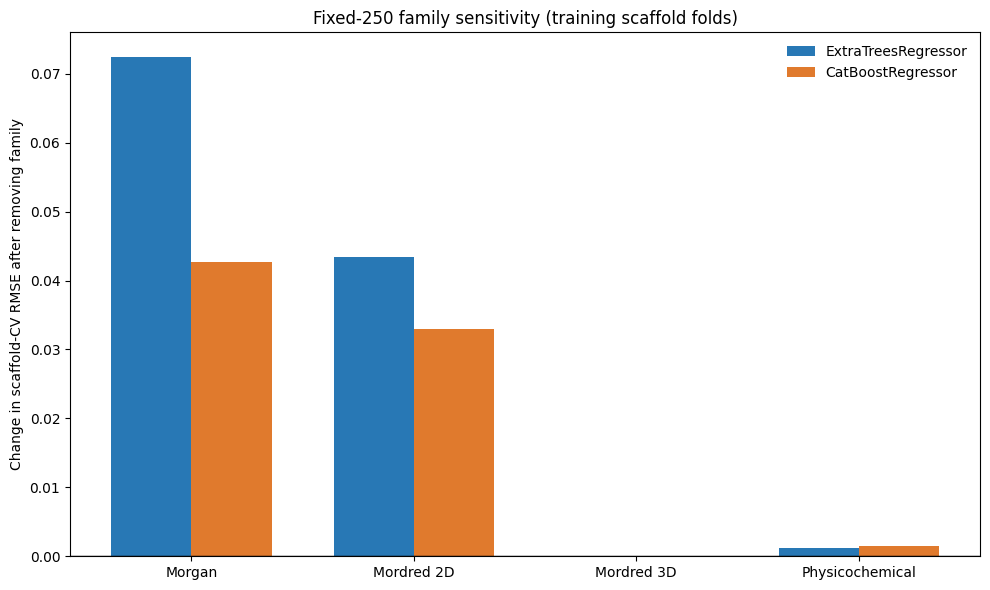

,model,variant,mean_fold_rmse,sd_fold_rmse,pooled_oof_rmse,pooled_oof_mae,pooled_oof_r2,n_features,delta_rmse_vs_all_features
0,CatBoostRegressor,all_features,0.598163,0.036062,0.596748,0.437376,0.756543,250,0.000000
1,CatBoostRegressor,without_mordred_2d,0.630752,0.031543,0.629775,0.463076,0.728849,104,0.033027
2,CatBoostRegressor,without_mordred_3d,0.598163,0.036062,0.596748,0.437376,0.756543,250,0.000000
3,CatBoostRegressor,without_morgan,0.641117,0.038534,0.639440,0.470768,0.720462,147,0.042692
4,CatBoostRegressor,without_physicochemical,0.598951,0.036640,0.598306,0.438315,0.755270,249,0.001558
5,ExtraTreesRegressor,all_features,0.576811,0.031669,0.576491,0.411388,0.772791,250,0.000000
6,ExtraTreesRegressor,without_mordred_2d,0.620812,0.030893,0.619957,0.434980,0.737238,104,0.043466
7,ExtraTreesRegressor,without_mordred_3d,0.576811,0.031669,0.576491,0.411388,0.772791,250,0.000000
8,ExtraTreesRegressor,without_morgan,0.650634,0.042599,0.648871,0.466801,0.712156,147,0.072380
9,ExtraTreesRegressor,without_physicochemical,0.577799,0.032541,0.577651,0.412399,0.771876,249,0.001159


Next: map the final ExtraTrees model’s Morgan-bit SHAP values onto structures.


In [7]:
# 6. Compare family-removal effects and save a table and figure.
import matplotlib.pyplot as plt

family_comparison = pd.concat([et_family_results, cat_family_results], ignore_index=True)
family_comparison.to_csv(STAGE_DIR / "tables/fixed250_family_ablation_both_models.csv", index=False)
plot_data = family_comparison.loc[family_comparison.variant.str.startswith("without_")].copy()
plot_data["omitted_family"] = plot_data["variant"].str.replace("without_", "", regex=False).str.replace("_", " ", regex=False)
order = ["morgan", "mordred 2d", "mordred 3d", "physicochemical"]
fig, ax = plt.subplots(figsize=(10, 6))
width = 0.36
positions = range(len(order))
for offset, (model, color) in enumerate([("ExtraTreesRegressor", "#2878B5"), ("CatBoostRegressor", "#E07A2D")]):
    vals = []
    for fam in order:
        row = plot_data.loc[(plot_data.model == model) & (plot_data.omitted_family == fam), "delta_rmse_vs_all_features"]
        vals.append(float(row.iloc[0]) if len(row) else 0.0)
    x = [pos + (offset - 0.5) * width for pos in positions]
    ax.bar(x, vals, width=width, label=model, color=color)
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(list(positions), [name.title() for name in order])
ax.set_ylabel("Change in scaffold-CV RMSE after removing family")
ax.set_title("Fixed-250 family sensitivity (training scaffold folds)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(STAGE_DIR / "figures/fixed250_family_ablation.png", dpi=300, bbox_inches="tight")
fig.savefig(STAGE_DIR / "figures/fixed250_family_ablation.pdf", bbox_inches="tight")
plt.show()
display(family_comparison.sort_values(["model", "variant"]).reset_index(drop=True))
print("Next: map the final ExtraTrees model’s Morgan-bit SHAP values onto structures.")


,model,case,chembl_id,predicted_pIC50,n_morgan_features_in_fixed250,n_present_morgan_bits_explained,figure
0,ExtraTreesRegressor,low,CHEMBL4763815,3.210712,103,12,C:\Users\USER\Documents\E\Code\outputs\10b_int...
1,ExtraTreesRegressor,median,CHEMBL6033164,6.179924,103,9,C:\Users\USER\Documents\E\Code\outputs\10b_int...
2,ExtraTreesRegressor,high,CHEMBL6010533,9.272691,103,15,C:\Users\USER\Documents\E\Code\outputs\10b_int...


,model,case,chembl_id,morgan_bit,bit_shap_pIC50,center_atom_index,radius,atom_indices,hashed_bit_occurrences_in_molecule
0,ExtraTreesRegressor,low,CHEMBL4763815,231,-0.159438,21,1,"3,21,22",1
1,ExtraTreesRegressor,low,CHEMBL4763815,976,-0.391893,22,2,"0,1,2,3,21,22,23",1
2,ExtraTreesRegressor,low,CHEMBL4763815,1899,-0.277862,21,2,"1,2,3,4,21,22,23",1
3,ExtraTreesRegressor,low,CHEMBL4763815,1693,-0.102610,1,1,"0,1,2,22",1
4,ExtraTreesRegressor,low,CHEMBL4763815,978,-0.116807,1,2,"0,1,2,3,21,22,23",1
5,ExtraTreesRegressor,low,CHEMBL4763815,1969,-0.115397,2,2,"0,1,2,3,4,21,22",1
6,ExtraTreesRegressor,low,CHEMBL4763815,314,0.000887,23,1,"22,23",1
7,ExtraTreesRegressor,low,CHEMBL4763815,2000,-0.044006,3,1,"2,3,4,21",1
8,ExtraTreesRegressor,low,CHEMBL4763815,1152,-0.005769,11,0,11,1
9,ExtraTreesRegressor,low,CHEMBL4763815,1145,0.003158,0,1,"0,1",1


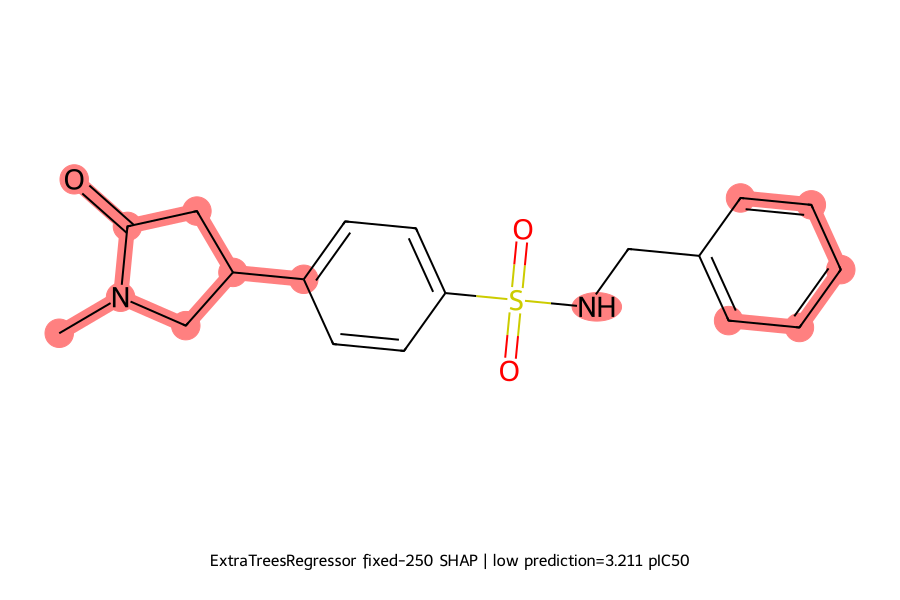

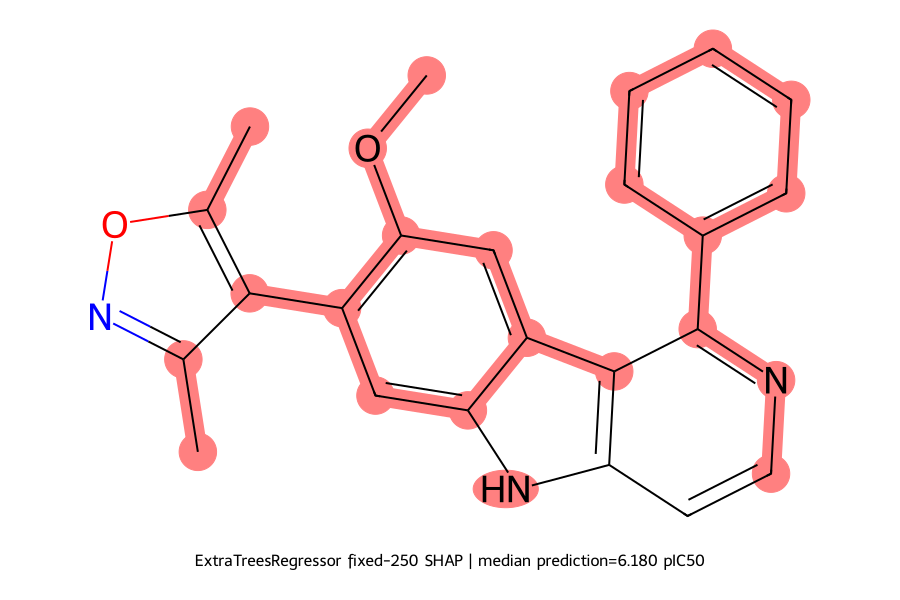

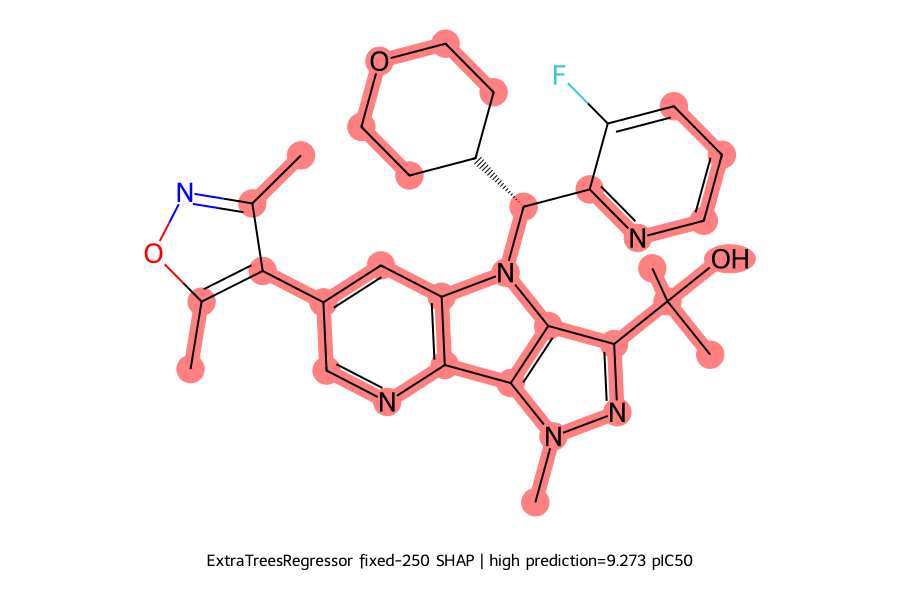

If no Morgan bits occur in the fixed 250, this model has no Morgan-bit map to draw.
Next: make the same structure maps for CatBoost.


In [8]:
# 7. ExtraTrees Morgan-bit explanations from the final Stage 08 model.
# Uses Stage 10 SHAP values for the exact fixed-250 model; no Morgan-only model is fitted.
et_morgan_cases, et_morgan_environments, et_morgan_images = draw_fixed250_morgan_highlights("ExtraTreesRegressor")
display(et_morgan_cases)
display(et_morgan_environments.head(30))
for image in et_morgan_images:
    display(image)
print("If no Morgan bits occur in the fixed 250, this model has no Morgan-bit map to draw.")
print("Next: make the same structure maps for CatBoost.")


,model,case,chembl_id,predicted_pIC50,n_morgan_features_in_fixed250,n_present_morgan_bits_explained,figure
0,CatBoostRegressor,low,CHEMBL4748673,2.993360,103,12,C:\Users\USER\Documents\E\Code\outputs\10b_int...
1,CatBoostRegressor,median,CHEMBL4848969,6.164433,103,8,C:\Users\USER\Documents\E\Code\outputs\10b_int...
2,CatBoostRegressor,high,CHEMBL6051531,9.236537,103,16,C:\Users\USER\Documents\E\Code\outputs\10b_int...


,model,case,chembl_id,morgan_bit,bit_shap_pIC50,center_atom_index,radius,atom_indices,hashed_bit_occurrences_in_molecule
0,CatBoostRegressor,low,CHEMBL4748673,231,-0.141346,11,1,"3,11,12",1
1,CatBoostRegressor,low,CHEMBL4748673,976,-0.257087,12,2,"0,1,2,3,11,12,13",1
2,CatBoostRegressor,low,CHEMBL4748673,1899,-0.234815,11,2,"1,2,3,4,11,12,13",1
3,CatBoostRegressor,low,CHEMBL4748673,1693,-0.102267,1,1,"0,1,2,12",1
4,CatBoostRegressor,low,CHEMBL4748673,978,-0.072669,1,2,"0,1,2,3,11,12,13",1
5,CatBoostRegressor,low,CHEMBL4748673,1969,-0.010462,2,2,"0,1,2,3,4,11,12",1
6,CatBoostRegressor,low,CHEMBL4748673,314,-0.011472,13,1,"12,13",1
7,CatBoostRegressor,low,CHEMBL4748673,2000,-0.045641,3,1,"2,3,4,11",1
8,CatBoostRegressor,low,CHEMBL4748673,1027,-0.013709,4,1,"3,4,5,9",1
9,CatBoostRegressor,low,CHEMBL4748673,1145,0.005795,0,1,"0,1",1


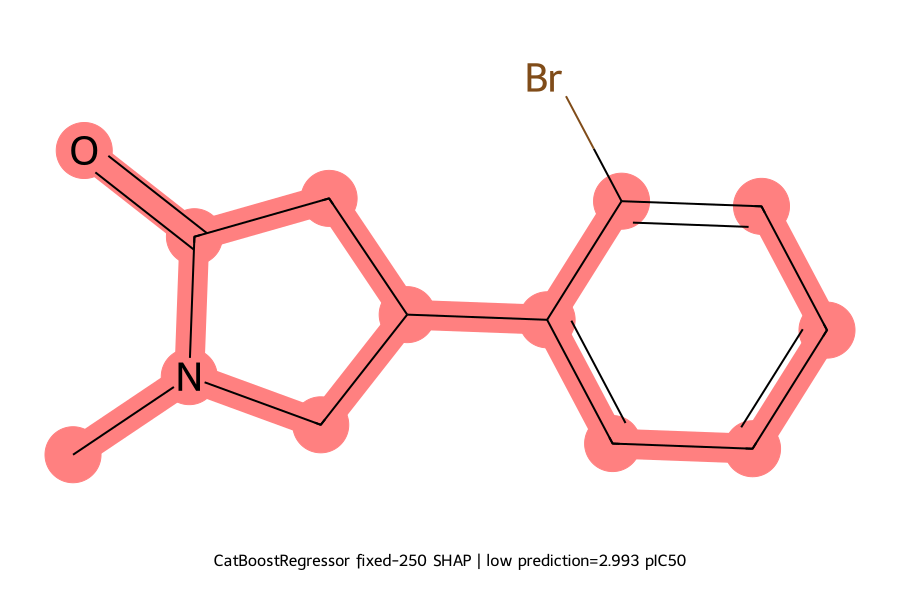

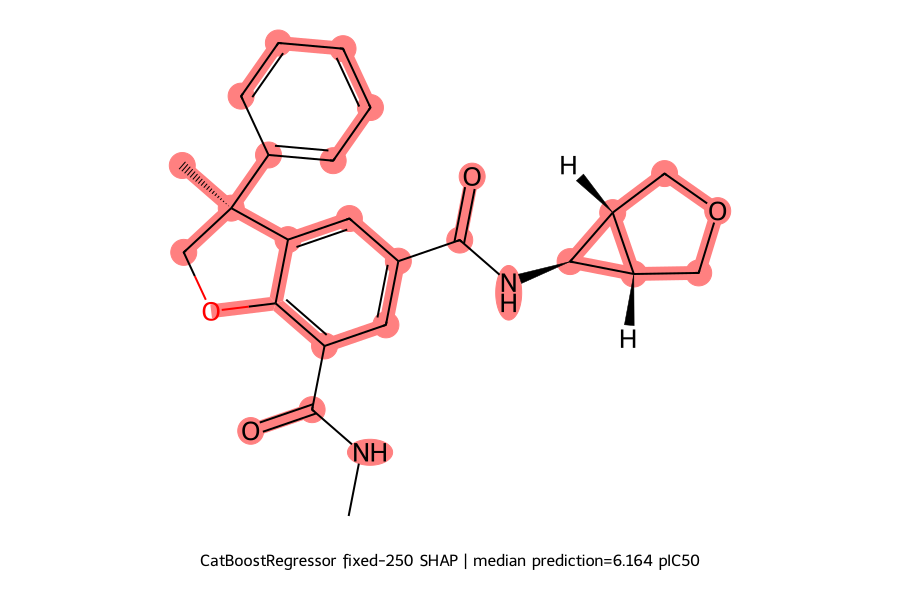

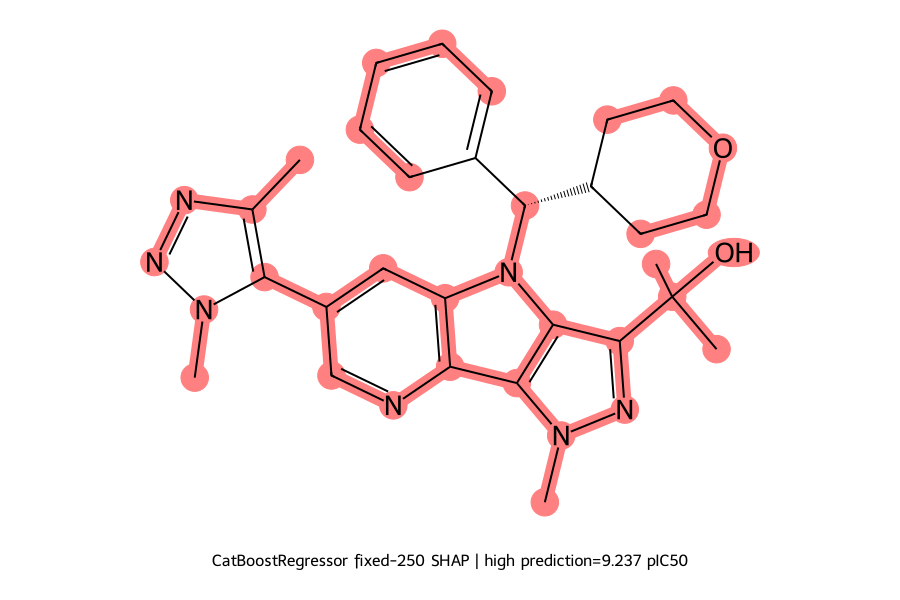

Next: identify a training-only congeneric series suitable for MolSHAP.


In [9]:
# 8. CatBoost Morgan-bit explanations from the final Stage 08 model.
cat_morgan_cases, cat_morgan_environments, cat_morgan_images = draw_fixed250_morgan_highlights("CatBoostRegressor")
display(cat_morgan_cases)
display(cat_morgan_environments.head(30))
for image in cat_morgan_images:
    display(image)
print("Next: identify a training-only congeneric series suitable for MolSHAP.")


In [10]:
# 9. Find and display candidate Bemis–Murcko series using training molecules only.
import pandas as pd
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

# Read structures only from the cleaned table; get activity from the training-only target file.
activity = pd.read_csv(
    OUTPUTS / "02_clean_data/tables/cleaned_activity.csv",
    usecols=["chembl_id", "canonical_smiles"],
    dtype={"chembl_id": str},
)
train_ids = pd.read_csv(OUTPUTS / "04_train_test_split/tables/train_ids.csv", dtype={"chembl_id": str})
train_ids["chembl_id"] = train_ids.chembl_id.astype(str)
activity["chembl_id"] = activity.chembl_id.astype(str)
train_activity = activity.merge(train_ids[["chembl_id", "group"]], on="chembl_id", how="inner", validate="one_to_one")
train_target = pd.read_parquet(OUTPUTS / "05_feature_selection/tables/train_target.parquet")["pIC50"]
train_target.index = train_target.index.astype(str)
train_activity["pIC50"] = train_activity.chembl_id.map(train_target)
if len(train_activity) != len(train_ids) or train_activity.pIC50.isna().any():
    raise ValueError("The cleaned training structures, IDs, and training-only target did not align.")

series = []
for scaffold, frame in train_activity.groupby("group", sort=False):
    if len(frame) < 8:
        continue
    series.append({"scaffold": scaffold, "n_molecules": len(frame), "n_unique_pIC50": frame.pIC50.nunique()})
series_table = pd.DataFrame(series).sort_values(["n_molecules", "n_unique_pIC50"], ascending=False).reset_index(drop=True)
display(series_table.head(15))
if series_table.empty:
    raise ValueError("No training scaffold series has at least eight molecules; MolSHAP needs a congeneric series.")

# Use the largest eligible training-only scaffold series. It is not selected using test activities.
MOLSHAP_SCAFFOLD = str(series_table.iloc[0].scaffold)
molshap_series = train_activity.loc[train_activity.group == MOLSHAP_SCAFFOLD, ["chembl_id", "canonical_smiles", "pIC50"]].copy()
molshap_series = molshap_series.rename(columns={"chembl_id": "ID", "canonical_smiles": "SMILES", "pIC50": "Activity"})
if len(molshap_series) < 8:
    raise ValueError("Selected training series is too small for the MolSHAP implementation.")
MOLSHAP_WORK = STAGE_DIR / "molshap_training_series"
MOLSHAP_WORK.mkdir(parents=True, exist_ok=True)
MOLSHAP_INPUT = MOLSHAP_WORK / "molshap_training_series.csv"
molshap_series.to_csv(MOLSHAP_INPUT, index=False)
print(f"Selected training-only series: {len(molshap_series)} molecules; {molshap_series.Activity.nunique()} distinct pIC50 values.")
print("The official MolSHAP workflow uses R-group decomposition and its own Morgan-based surrogate model; it does not explain the Stage 08 mixed-feature models.")
display(molshap_series.head())
print("Next: fetch the authors’ pinned MolSHAP source into the output folder and prepare its scripts.")

,scaffold,n_molecules,n_unique_pIC50
0,c1ccc2c(c1)ncc1nncn12,269,91
1,c1ccc(Nc2ccnc(Nc3ccc(N4CCNCC4)cc3)n2)cc1,84,72
2,c1ccc(CCc2nc3c4c(ccc3n2C2CCCCC2)NCCC4)cc1,78,4
3,c1ccc(Nc2nc3c4c(ccc3n2C2CCCCC2)NCCC4)cc1,48,3
4,O=c1[nH]cc(-c2ccccc2)c2ccccc12,45,15
5,c1ccc(C2=NCc3nncn3-c3sccc32)cc1,42,37
6,O=C1CCNc2c(cccc2-c2ccccc2)N1,39,39
7,c1ccc(Cn2ccc3c2ccc2nncn23)cc1,35,2
8,c1ccc(-n2ccc3cnc(Nc4ccc(N5CCNCC5)cc4)nc32)cc1,33,29
9,O=C1Nc2ccc(-c3cnoc3)cc2C1c1ccccc1,30,28


Selected training-only series: 269 molecules; 91 distinct pIC50 values.
The official MolSHAP workflow uses R-group decomposition and its own Morgan-based surrogate model; it does not explain the Stage 08 mixed-feature models.


,ID,SMILES,Activity
11,CHEMBL5881238,CCOc1cc2nc(NCCCCNC(=O)CC(C)C)c3nnc(C)n3c2cc1OCC,7.301030
14,CHEMBL5963468,COc1ccc2c(c1)nc(NCCCCNC(=O)[C@@H](NC(=O)[C@@H]...,7.920819
15,CHEMBL5794735,COc1ccc2c(c1)nc(NCCCCNC(=O)[C@@H](NC(=O)CC(C)C...,7.853872
17,CHEMBL6027394,CSc1ccc2c(c1)nc(NCCCCNC(=O)OC(C)(C)C)c1nnc(C)n12,7.251812
22,CHEMBL5951681,CCNC(=O)NCCCCNc1nc2cc(OC)c(OC)cc2n2c(C)nnc12,7.327902


Next: fetch the authors’ pinned MolSHAP source into the output folder and prepare its scripts.


In [11]:
# 10. Fetch the authors’ MolSHAP implementation at a fixed commit and prepare an isolated working copy.
# Internet access is needed for this cell. The code is downloaded at run time; it is not bundled into the project ZIP.
import shutil
import urllib.request
import zipfile

MOLSHAP_COMMIT = "f3a22216d040017731d99671dec769477c69eef8"
archive_path = MOLSHAP_WORK / "molshap_source.zip"
repo_url = f"https://github.com/tiantz17/MolSHAP/archive/{MOLSHAP_COMMIT}.zip"
if not archive_path.is_file():
    print("Downloading the pinned MolSHAP source...")
    urllib.request.urlretrieve(repo_url, archive_path)
extract_dir = MOLSHAP_WORK / "source"
extract_dir.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(archive_path) as archive:
    archive.extractall(extract_dir)
source_root = next(extract_dir.glob("MolSHAP-*"))
for filename in ("decompose.py", "molshap.py", "model.py", "utils.py"):
    shutil.copy2(source_root / filename, MOLSHAP_WORK / filename)
# Adapt the downloaded utility to this project’s Morgan settings and modern RDKit API.
from src.utils import load_config
mol_config = load_config()
morgan_bits = int(mol_config.get("fingerprint_bits", 2048))
morgan_radius = int(mol_config.get("fingerprint_radius", 2))
morgan_chirality = bool(mol_config.get("use_chirality", True))
utils_path = MOLSHAP_WORK / "utils.py"
utils_text = utils_path.read_text(encoding="utf-8")
utils_text = utils_text.replace("from rdkit.Chem import AllChem", "from rdkit.Chem import AllChem\nfrom rdkit.Chem import rdFingerprintGenerator")
old_fingerprint_call = "AllChem.GetMorganFingerprintAsBitVect(mol,radius,nBits=nBits,useChirality=True)"
new_fingerprint_call = f"rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=nBits, includeChirality={morgan_chirality}).GetFingerprint(mol)"
if utils_text.count(old_fingerprint_call) != 2:
    raise RuntimeError("Could not find both legacy Morgan calls in the pinned MolSHAP utility.")
utils_text = utils_text.replace(old_fingerprint_call, new_fingerprint_call)
utils_text = utils_text.replace("nBits=1024, radius=2", f"nBits={morgan_bits}, radius={morgan_radius}")
utils_path.write_text(utils_text, encoding="utf-8")
# The paper's script continues into automated compound optimization after it
# saves the MolSHAP fragment scores. Keep this notebook focused on explanation.
script_path = MOLSHAP_WORK / "molshap.py"
script_text = script_path.read_text(encoding="utf-8")
optimization_marker = "print('-'*60)\nprint(\"Compound optimization\")"
if optimization_marker not in script_text:
    raise RuntimeError("Could not locate the MolSHAP candidate-generation section; review the pinned source before proceeding.")
script_path.write_text(script_text.split(optimization_marker, 1)[0], encoding="utf-8")
print("MolSHAP candidate-generation code is omitted; fragment explanations are retained.")
print(f"MolSHAP Morgan settings: radius={morgan_radius}, bits={morgan_bits}, chirality={morgan_chirality}")
print("Morgan fingerprints use RDKit MorganGenerator to avoid the legacy deprecation warning.")
print(f"Pinned source commit: {MOLSHAP_COMMIT}")
print(f"Working folder: {MOLSHAP_WORK}")
print("Next: decompose the selected molecules into a common core and R-groups.")

MolSHAP candidate-generation code is omitted; fragment explanations are retained.
MolSHAP Morgan settings: radius=2, bits=2048, chirality=True
Morgan fingerprints use RDKit MorganGenerator to avoid the legacy deprecation warning.
Pinned source commit: f3a22216d040017731d99671dec769477c69eef8
Working folder: C:\Users\USER\Documents\E\Code\outputs\10b_interpretation\molshap_training_series
Next: decompose the selected molecules into a common core and R-groups.


In [12]:
# 11. Run the authors’ R-group decomposition and inspect its result before MolSHAP.
import subprocess

result = subprocess.run(
    [sys.executable, "decompose.py", "-i", MOLSHAP_INPUT.name, "-o", "./"],
    cwd=MOLSHAP_WORK,
    text=True,
    capture_output=True,
)
print(result.stdout[-5000:])
if result.returncode != 0:
    print(result.stderr[-5000:])
    raise RuntimeError("MolSHAP decomposition failed. Stop here and share this cell's full error.")
import pickle

decomp_path = MOLSHAP_WORK / "molshap_training_series_decomp.pk"
core, decomposed, success_indices = pickle.load(open(decomp_path, "rb"))
print(f"Decomposition succeeded for {len(success_indices)} of {len(molshap_series)} training molecules.")
print("Common core:", Chem.MolToSmiles(core))
if len(decomposed) < 8:
    raise RuntimeError("Fewer than eight training compounds decomposed successfully. Stop and inspect another scaffold series.")
rgroup_counts = {}
for row in decomposed:
    for site, fragment in row.items():
        rgroup_counts.setdefault(site, set()).add(Chem.MolToSmiles(fragment))
rgroup_summary = pd.DataFrame([{"R_group_site": site, "n_distinct_fragments": len(fragments)} for site, fragments in rgroup_counts.items()]).sort_values("R_group_site")
display(rgroup_summary)
print("Next: calculate MolSHAP contributions. This uses only the training-series activity values.")

Side-chain decomposition for molshap_training_series.csv
269 compounds found.
Scarffold: 26 atoms, C(CC(Nc1nc2c([*:7])c([*:6])c([*:5])c([*:4])c2n2c(C[*:3])nnc12)[*:2])C[*:1]
Side chains: 7, [R1, R2, R3, R4, R5, R6, R7]
269 compounds in total, 269 succeed, 0 failed.

Decomposition succeeded for 269 of 269 training molecules.
Common core: CCCCNC1:N:C2:C:C:C:C:C:2:N2:C(C):N:N:C:1:2


,R_group_site,n_distinct_fragments
0,Core,1
1,R1,69
2,R2,2
3,R3,4
4,R4,3
5,R5,25
6,R6,23
7,R7,5


Next: calculate MolSHAP contributions. This uses only the training-series activity values.


In [13]:
# 12. Run MolSHAP and display the substituent contribution ranking.
# This run stops after saving fragment contributions; automated candidate generation was omitted in the setup cell.
# The authors' script also prints an internal random-split surrogate diagnostic; it is not Stage 08 scaffold-CV or test performance.
result = subprocess.run(
    [sys.executable, "molshap.py", "-i", MOLSHAP_INPUT.name, "-o", "./"],
    cwd=MOLSHAP_WORK,
    text=True,
    capture_output=True,
)
print(result.stdout[-6000:])
if result.returncode != 0:
    print(result.stderr[-6000:])
    raise RuntimeError("MolSHAP analysis failed. Stop here and share this cell's full error.")
import pickle

contrib_path = MOLSHAP_WORK / "molshap_training_series_contrib_by_smiles.pk"
contributions = pickle.load(open(contrib_path, "rb"))
molshap_contributions = pd.DataFrame([{"R_group_fragment_smiles": fragment, "MolSHAP_contribution": float(value)} for fragment, value in contributions.items()]).sort_values("MolSHAP_contribution", ascending=False, kind="stable").reset_index(drop=True)
molshap_contributions.to_csv(STAGE_DIR / "tables/molshap_training_series_fragment_contributions.csv", index=False)
print("R-group fragment contributions from the training-only series:")
display(molshap_contributions)
print("The full MolSHAP outputs are saved in:", MOLSHAP_WORK)
print("Next: review the analysis outputs and confirm files were written.")

Exception in thread Thread-257 (_readerthread):
Traceback (most recent call last):
  File "C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\threading.py", line 1009, in _bootstrap_inner
    self.run()
  File "C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\threading.py", line 946, in run
    self._target(*self._args, **self._kwargs)
  File "C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1494, in _readerthread
    buffer.append(fh.read())
  File "C:\Users\USER\AppData\Local\Programs\Python\Python310\lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
UnicodeDecodeError: 'charmap' codec can't decode byte 0x8f in position 2086: character maps to <undefined>


MolSHAP analysis for molshap_training_series.csv
Using 269 compounds for analysis.
------------------------------------------------------------
Side-chain candidates:
Core: 1
R1: 69
R2: 2
R3: 4
R4: 3
R5: 25
R6: 23
R7: 5
------------------------------------------------------------
Side-chain ranking pairs:
R5: 78
R1: 1020
R6: 79
R3: 7
R4: 1
R7: 2
------------------------------------------------------------
Core background: C(CC(Nc1nc2c([*:7])c([*:6])c([*:5])c([*:4])c2n2c(C[*:3])nnc12)[*:2])C[*:1]
R1 background: [H][*:1]
R2 background: [H][*:2]
R3 background: [H][*:3]
R4 background: [H][*:4]
R5 background: [H][*:5]
R6 background: [H][*:6]
R7 background: [H][*:7]
------------------------------------------------------------
Model training
{'Regression': {'PCC': np.float64(0.23904244208134673), 'R2': -0.9724076389966354}}
------------------------------------------------------------
Model analysing
0 
Seen: {'MacroF1': 0.6942450142450142, 'Accuracy': 0.6997333333333333}
Unseen: {'MacroF1': 0

,R_group_fragment_smiles,MolSHAP_contribution
0,CCCOC(=O)N[C@H](C(=O)N[*:1])C(C)C,2.047450
1,CC(C)COC(=O)N[C@H](C(=O)N[*:1])C(C)C,1.947417
2,CC(C)[C@H](O)C(=O)N[*:1],1.870835
3,CC(C)OC(=O)N[C@H](C(=O)N[*:1])C(C)C,1.746249
4,CC(C)[C@H](Br)C(=O)N[*:1],1.730109
...,...,...
127,CCCN[*:5],-0.237961
128,C[*:4],-0.259480
129,NN[*:5],-0.356093
130,C[*:3].C[*:3],-0.361364


The full MolSHAP outputs are saved in: C:\Users\USER\Documents\E\Code\outputs\10b_interpretation\molshap_training_series
Next: review the analysis outputs and confirm files were written.


In [14]:
# 13. Final output inventory and completion check.
from src.utils import write_manifest

output_files = sorted(p for p in STAGE_DIR.rglob("*") if p.is_file())
output_table = pd.DataFrame([{"file": str(p.relative_to(STAGE_DIR)), "size_kB": round(p.stat().st_size / 1024, 1)} for p in output_files])
display(output_table)
manifest_path = STAGE_DIR / "manifest.json"
manifest_outputs = [p for p in output_files if p != manifest_path]
write_manifest(
    "10b_interpretation",
    {
        "feature_set": "exact fixed 250 features selected in Stage 05; Stage 03 candidate feature pool is not reloaded or re-ranked",
        "family_shap": "summarized from Stage 10 SHAP values for final Stage 08 ExtraTrees and CatBoost models",
        "family_ablation": "fixed-250 leave-one-family-out scaffold-CV sensitivity analysis; not an independent performance estimate because Stage 05 selected features on the full training partition",
        "morgan_structural_explanations": "Stage 10 Morgan-bit SHAP values mapped to locked-test structures for the final Stage 08 models; no auxiliary Morgan-only model",
        "molshap": "authors' implementation at pinned commit; training-only congeneric series",
        "molshap_optimization_candidates_generated": False,
    },
    inputs=[
        OUTPUTS / "05_feature_selection/tables/train_selected_features.parquet",
        OUTPUTS / "05_feature_selection/tables/train_target.parquet",
        OUTPUTS / "04_train_test_split/tables/train_ids.csv",
        OUTPUTS / "04_train_test_split/tables/test_ids.csv",
        OUTPUTS / "05_feature_selection/tables/selected_features.csv",
        OUTPUTS / "07_optuna_tuning/tables/optuna_best_params.json",
        OUTPUTS / "10_shap_interpretation/tables/test_shap_values_ExtraTreesRegressor.parquet",
        OUTPUTS / "10_shap_interpretation/tables/test_shap_values_CatBoostRegressor.parquet",
    ],
    outputs=manifest_outputs,
)
print(f"Saved {len(output_files) + 1} files under {STAGE_DIR}")
print(f"Manifest: {manifest_path}")
print("Interpret findings as model explanations and dataset-level structure–activity evidence, not proof of a binding mechanism.")


,file,size_kB
0,figures\fixed250_family_ablation.pdf,15.5
1,figures\fixed250_family_ablation.png,122.2
2,figures\fixed250_morgan_SHAP_CatBoost_high_CHE...,74.4
3,figures\fixed250_morgan_SHAP_CatBoost_low_CHEM...,58.2
4,figures\fixed250_morgan_SHAP_CatBoost_median_C...,60.7
5,figures\fixed250_morgan_SHAP_ExtraTrees_high_C...,69.5
6,figures\fixed250_morgan_SHAP_ExtraTrees_low_CH...,45.5
7,figures\fixed250_morgan_SHAP_ExtraTrees_median...,73.8
8,molshap_training_series\__pycache__\model.cpyt...,5.4
9,molshap_training_series\__pycache__\utils.cpyt...,8.4


Saved 46 files under C:\Users\USER\Documents\E\Code\outputs\10b_interpretation
Manifest: C:\Users\USER\Documents\E\Code\outputs\10b_interpretation\manifest.json
Interpret findings as model explanations and dataset-level structure–activity evidence, not proof of a binding mechanism.


## Reading the results

- `all_features` uses all 250 fixed Stage 05 features. A `without_*` row removes only the named family from that list; there is no return to the 3,291-feature candidate pool and no fresh ranking.
- A positive `delta_rmse_vs_all_features` means removing a family raised the scaffold-CV RMSE. Because Stage 05 selected the 250 using the full training partition, treat this comparison as a descriptive sensitivity analysis, not an independent validation score. Stage 08 remains the source of the reported CV and test metrics.
- Family SHAP totals and Morgan maps use the existing Stage 10 SHAP explanations from the final Stage 08 ExtraTrees and CatBoost models. The displayed Morgan substructures are limited to Morgan bits present in the fixed 250.
- MolSHAP ranks substituent fragments in a training-only congeneric series using its own surrogate. It is distinct from the Stage 08 final models. Treat fragment scores as model explanations, not causal proof.
- Stage 10B does not load locked-test activity values or retune/select final models from test results.
